# Setup

In [2]:
# Import packages.
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt

In [3]:
PICKLE_PATH = Path('pickles/sim_broad_signal_plus_peak.pkl')

with PICKLE_PATH.open('rb') as handle:
    data = pickle.load(handle)

matrix = np.asarray(data['matrix'], dtype=float)
signal_a = np.asarray(data['signal_a'], dtype=float)
signal_b = np.asarray(data['signal_b'], dtype=float)

# Recover the constrained regions belonging to each surviving mode

In [4]:
def surviving_mode_regions(data):
    """Return one pooled mask and its member masks for every surviving mode."""
    source_modes = data.get('modes')
    if source_modes is None:
        source_modes = data.get('selection', {}).get('modes', [])
    modes = []

    for fallback_id, source_mode in enumerate(source_modes, start=1):
        mode_id = int(source_mode.get('mode_id', fallback_id))
        constrained_regions = source_mode.get('constrained_regions', {})
        requested_members = source_mode.get('islands', constrained_regions.keys())

        member_masks = {}
        for island_id in requested_members:
            island_id = int(island_id)
            if island_id not in constrained_regions:
                continue
            mask = np.asarray(constrained_regions[island_id], dtype=bool)
            if mask.shape != matrix.shape:
                raise ValueError(
                    f'Mode {mode_id}, island {island_id} has mask shape {mask.shape}; '
                    f'expected {matrix.shape}.'
                )
            if mask.any():
                member_masks[island_id] = mask

        if not member_masks:
            raise ValueError(f'Mode {mode_id} has no nonempty constrained regions.')

        # All member islands contribute to one mode-level fit.
        mode_mask = np.logical_or.reduce(list(member_masks.values()))
        rows, columns = np.where(mode_mask)
        modes.append({
            'mode_id': mode_id,
            'island_ids': tuple(member_masks),
            'member_masks': member_masks,
            'mask': mode_mask,
            'x_min': int(columns.min()),
            'x_max': int(columns.max()),
            'y_min': int(rows.min()),
            'y_max': int(rows.max()),
            'lag': source_mode.get('lag', np.nan),
            'lag_min': source_mode.get('lag_min', np.nan),
            'lag_max': source_mode.get('lag_max', np.nan),
        })

    return modes


modes = surviving_mode_regions(data)
for mode in modes:
    print({
        'mode_id': mode['mode_id'],
        'island_ids': mode['island_ids'],
        'lag': mode['lag'],
        'lag_range': (mode['lag_min'], mode['lag_max']),
        'bounds': (mode['x_min'], mode['x_max'], mode['y_min'], mode['y_max']),
        'mode_pixels': int(mode['mask'].sum()),
    })

{'mode_id': 1, 'island_ids': (1, 2, 3), 'lag': 5.0, 'lag_range': (-89.0, 75.5), 'bounds': (48, 242, 0, 299), 'mode_pixels': 25118}


# Quantile matching inside the mode masks

In [5]:
def mode_crop(array, mode):
    return array[
        mode['y_min']:mode['y_max'] + 1,
        mode['x_min']:mode['x_max'] + 1,
    ]


def weighted_quantile_positions(weights, quantiles):
    """Convert cumulative-mass quantiles to fractional array positions."""
    weights = np.clip(np.asarray(weights, dtype=float), 0, None)
    if weights.sum() == 0:
        weights = np.ones_like(weights)

    cumulative = np.r_[0.0, np.cumsum(weights) / weights.sum()]
    positions = np.linspace(0, len(weights) - 1, len(weights) + 1)
    return np.interp(quantiles, cumulative, positions)


def smooth_marginal(weights, sigma):
    """Gaussian smoothing without requiring scipy."""
    if sigma <= 0:
        return weights

    radius = max(1, int(np.ceil(4 * sigma)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
    kernel /= kernel.sum()
    padded = np.pad(weights, radius, mode='edge')
    return np.convolve(padded, kernel, mode='valid')


def prepare_marginal(weights, signal_influence, smoothing_sigma, support):
    """Blend the observed marginal with uniform mass on supported positions."""
    support = np.asarray(support, dtype=bool)
    weights = smooth_marginal(np.asarray(weights, dtype=float), smoothing_sigma)
    weights = np.where(support, weights, 0)
    if weights.sum() == 0:
        observed = support / support.sum()
    else:
        observed = weights / weights.sum()

    uniform = support / support.sum()
    return signal_influence * observed + (1 - signal_influence) * uniform


def project_points_to_mask(x, y, mask):
    """Move only invalid quantile points to their nearest valid mode pixel."""
    valid_rows, valid_columns = np.where(mask)
    if len(valid_rows) == 0:
        raise ValueError('Cannot project onto an empty mode mask.')

    projected_x = np.asarray(x, dtype=float).copy()
    projected_y = np.asarray(y, dtype=float).copy()
    rounded_x = np.rint(projected_x).astype(int)
    rounded_y = np.rint(projected_y).astype(int)
    in_bounds = (
        (rounded_x >= 0) & (rounded_x < mask.shape[1])
        & (rounded_y >= 0) & (rounded_y < mask.shape[0])
    )
    valid = np.zeros(len(projected_x), dtype=bool)
    valid[in_bounds] = mask[rounded_y[in_bounds], rounded_x[in_bounds]]

    for index in np.where(~valid)[0]:
        distances = (valid_columns - projected_x[index]) ** 2 + (
            valid_rows - projected_y[index]
        ) ** 2
        nearest = int(np.argmin(distances))
        projected_x[index] = valid_columns[nearest]
        projected_y[index] = valid_rows[nearest]

    return projected_x, projected_y


def quantile_matching_line(
    matrix,
    mode,
    n_points=128,
    signal_influence=1.0,
    signal_power=1.0,
    smoothing_sigma=0.0,
):
    if not 0 <= signal_influence <= 1:
        raise ValueError('signal_influence must be between 0 and 1.')
    if signal_power <= 0:
        raise ValueError('signal_power must be positive.')

    crop = mode_crop(matrix, mode)
    mask_crop = mode_crop(mode['mask'], mode)

    # Signal outside every constrained mode region is completely excluded.
    # Scaling by the peak changes no relative weights and prevents overflow
    # when intentionally testing very large signal powers.
    positive_crop = np.where(mask_crop, np.clip(crop, 0, None), 0)
    peak = positive_crop.max()
    weighted_crop = (positive_crop / peak) ** signal_power if peak > 0 else positive_crop
    b_marginal = prepare_marginal(
        weighted_crop.sum(axis=0), signal_influence, smoothing_sigma,
        support=mask_crop.any(axis=0),
    )
    a_marginal = prepare_marginal(
        weighted_crop.sum(axis=1), signal_influence, smoothing_sigma,
        support=mask_crop.any(axis=1),
    )
    quantiles = np.linspace(0, 1, n_points)

    x = weighted_quantile_positions(b_marginal, quantiles) + mode['x_min']
    y = weighted_quantile_positions(a_marginal, quantiles) + mode['y_min']

    # Marginal quantiles can pair coordinates that are individually valid but
    # jointly outside a rhombus. Project those pairs back to the mode support.
    return project_points_to_mask(x, y, mode['mask'])


def quantile_nucleotide_mapping(quantile_x, quantile_y):
    """Evaluate the continuous curve at each integer B position."""
    unique_x, first_indices = np.unique(quantile_x, return_index=True)
    unique_y = quantile_y[first_indices]
    b_positions = np.arange(np.ceil(unique_x[0]), np.floor(unique_x[-1]) + 1)
    a_continuous = np.interp(b_positions, unique_x, unique_y)
    a_nearest = np.rint(a_continuous).astype(int)
    return b_positions.astype(int), a_continuous, a_nearest

# One straight line, angle, and displacement per mode

In [6]:
def clip_infinite_line_to_mask(center, direction, mask):
    """Return the pieces of an infinite line lying inside True mask pixels."""
    center = np.asarray(center, dtype=float)
    direction = np.asarray(direction, dtype=float)
    norm = np.linalg.norm(direction)
    if norm == 0:
        raise ValueError('Cannot clip a line with zero direction.')
    direction = direction / norm

    intervals = []
    rows, columns = np.where(mask)
    tolerance = 1e-10

    # Treat each valid nucleotide as a one-by-one square centered on its index.
    for row, column in zip(rows, columns):
        lower, upper = -np.inf, np.inf
        for coordinate, velocity, minimum, maximum in (
            (center[0], direction[0], column - 0.5, column + 0.5),
            (center[1], direction[1], row - 0.5, row + 0.5),
        ):
            if abs(velocity) <= tolerance:
                if not minimum <= coordinate <= maximum:
                    lower, upper = 1, 0
                    break
            else:
                first = (minimum - coordinate) / velocity
                second = (maximum - coordinate) / velocity
                lower = max(lower, min(first, second))
                upper = min(upper, max(first, second))

        if lower <= upper + tolerance:
            intervals.append((lower, upper))

    if not intervals:
        return np.array([np.nan]), np.array([np.nan])

    intervals.sort()
    merged = [list(intervals[0])]
    for lower, upper in intervals[1:]:
        if lower <= merged[-1][1] + tolerance:
            merged[-1][1] = max(merged[-1][1], upper)
        else:
            merged.append([lower, upper])

    x, y = [], []
    for lower, upper in merged:
        start = center + lower * direction
        end = center + upper * direction
        if x:
            x.append(np.nan)
            y.append(np.nan)
        x.extend([start[0], end[0]])
        y.extend([start[1], end[1]])

    return np.asarray(x), np.asarray(y)


def mask_polyline(x, y, mask):
    """Exactly clip every quantile-curve segment to the True mask pixels."""
    valid_rows, valid_columns = np.where(mask)
    output_x, output_y = [], []
    last_end = None
    tolerance = 1e-10

    for index in range(len(x) - 1):
        start = np.array([x[index], y[index]], dtype=float)
        end = np.array([x[index + 1], y[index + 1]], dtype=float)
        direction = end - start

        # Only pixels whose squares overlap this segment's bounding box can matter.
        candidates = (
            (valid_columns + 0.5 >= min(start[0], end[0]))
            & (valid_columns - 0.5 <= max(start[0], end[0]))
            & (valid_rows + 0.5 >= min(start[1], end[1]))
            & (valid_rows - 0.5 <= max(start[1], end[1]))
        )
        intervals = []

        for row, column in zip(valid_rows[candidates], valid_columns[candidates]):
            lower, upper = 0.0, 1.0
            for coordinate, velocity, minimum, maximum in (
                (start[0], direction[0], column - 0.5, column + 0.5),
                (start[1], direction[1], row - 0.5, row + 0.5),
            ):
                if abs(velocity) <= tolerance:
                    if not minimum <= coordinate <= maximum:
                        lower, upper = 1, 0
                        break
                else:
                    first = (minimum - coordinate) / velocity
                    second = (maximum - coordinate) / velocity
                    lower = max(lower, min(first, second))
                    upper = min(upper, max(first, second))

            if lower <= upper + tolerance:
                intervals.append((lower, upper))

        intervals.sort()
        merged = []
        for lower, upper in intervals:
            if merged and lower <= merged[-1][1] + tolerance:
                merged[-1][1] = max(merged[-1][1], upper)
            else:
                merged.append([lower, upper])

        for lower, upper in merged:
            clipped_start = start + lower * direction
            clipped_end = start + upper * direction
            if last_end is None or not np.allclose(last_end, clipped_start):
                if output_x:
                    output_x.append(np.nan)
                    output_y.append(np.nan)
                output_x.append(clipped_start[0])
                output_y.append(clipped_start[1])
            output_x.append(clipped_end[0])
            output_y.append(clipped_end[1])
            last_end = clipped_end

        if not merged:
            last_end = None

    if not output_x:
        return np.array([np.nan]), np.array([np.nan])
    return np.asarray(output_x), np.asarray(output_y)


def quantile_angle_line(
    quantile_x,
    quantile_y,
    mode,
    lower_quantile=0.20,
    upper_quantile=0.80,
):
    """Summarize the pooled mode quantiles with one constrained straight line."""
    if not 0 < lower_quantile < 0.5 < upper_quantile < 1:
        raise ValueError('Use lower < 0.5 < upper, all strictly between 0 and 1.')

    quantile_grid = np.linspace(0, 1, len(quantile_x))
    requested = np.array([lower_quantile, 0.5, upper_quantile])
    b_low, b_median, b_high = np.interp(requested, quantile_grid, quantile_x)
    a_low, a_median, a_high = np.interp(requested, quantile_grid, quantile_y)

    # Interpolation can land between valid pixels, so constrain the landmarks too.
    landmark_b, landmark_a = project_points_to_mask(
        np.array([b_low, b_median, b_high]),
        np.array([a_low, a_median, a_high]),
        mode['mask'],
    )
    b_low, b_median, b_high = landmark_b
    a_low, a_median, a_high = landmark_a

    delta_b = b_high - b_low
    delta_a = a_high - a_low
    if np.hypot(delta_b, delta_a) == 0:
        raise ValueError('The selected mode quantiles have no measurable span.')

    center = np.array([b_median, a_median])
    direction = np.array([delta_b, delta_a])
    straight_x, straight_y = clip_infinite_line_to_mask(
        center, direction, mode['mask']
    )

    box_delta_b = mode['x_max'] - mode['x_min']
    box_delta_a = mode['y_max'] - mode['y_min']
    if box_delta_b == 0 or box_delta_a == 0:
        raise ValueError('Angle metrics require a mode with nonzero width and height.')

    signal_slope = delta_a / delta_b if delta_b != 0 else np.inf
    box_slope = box_delta_a / box_delta_b
    signal_angle = np.degrees(np.arctan2(delta_a, delta_b))
    box_angle = np.degrees(np.arctan2(box_delta_a, box_delta_b))

    median_from_origin = np.array([
        b_median - mode['x_min'],
        a_median - mode['y_min'],
    ])
    box_direction = np.array([box_delta_b, box_delta_a], dtype=float)
    displacement_nt = (
        box_direction[0] * median_from_origin[1]
        - box_direction[1] * median_from_origin[0]
    ) / np.linalg.norm(box_direction)
    median_b_normalized = median_from_origin[0] / box_delta_b
    median_a_normalized = median_from_origin[1] / box_delta_a
    displacement_normalized = (
        median_a_normalized - median_b_normalized
    ) / np.sqrt(2)

    metrics = {
        'signal_angle_deg': signal_angle,
        'box_angle_deg': box_angle,
        'angle_offset_deg': signal_angle - box_angle,
        'signal_slope': signal_slope,
        'box_slope': box_slope,
        'relative_slope': signal_slope / box_slope,
        'median_b': b_median,
        'median_a': a_median,
        'median_lag_b_minus_a': b_median - a_median,
        'median_displacement_nt': displacement_nt,
        'median_displacement_normalized': displacement_normalized,
    }
    return straight_x, straight_y, metrics

# Build one result per mode

In [7]:
QUANTILE_PARAMETERS = {
    'signal_influence': 1.0,  # 0 = uniform marginals; 1 = fully signal-driven
    'signal_power': 1.0,      # >1 emphasizes peaks; <1 flattens them
    'smoothing_sigma': 0.0,   # larger values ignore finer-scale variation
    'n_points': 128,          # drawing resolution only
}

ANGLE_QUANTILES = (0.20, 0.80)

mode_lines = {}
for mode in modes:
    mode_id = mode['mode_id']
    quantile_x, quantile_y = quantile_matching_line(
        matrix, mode, **QUANTILE_PARAMETERS
    )
    visible_quantile_x, visible_quantile_y = mask_polyline(
        quantile_x, quantile_y, mode['mask']
    )
    straight_x, straight_y, metrics = quantile_angle_line(
        quantile_x, quantile_y, mode,
        lower_quantile=ANGLE_QUANTILES[0],
        upper_quantile=ANGLE_QUANTILES[1],
    )

    mode_lines[mode_id] = {
        'quantile': (quantile_x, quantile_y),
        'visible_quantile': (visible_quantile_x, visible_quantile_y),
        'straight': (straight_x, straight_y),
        'metrics': metrics,
    }

# Compare the mode-level metrics

In [8]:
metric_rows = [
    {
        'mode_id': mode['mode_id'],
        'n_islands': len(mode['island_ids']),
        **mode_lines[mode['mode_id']]['metrics'],
    }
    for mode in modes
]

columns = [
    ('mode_id', 'mode'),
    ('n_islands', 'islands'),
    ('signal_angle_deg', 'angle'),
    ('angle_offset_deg', 'angle offset'),
    ('signal_slope', 'slope'),
    ('relative_slope', 'relative slope'),
    ('median_lag_b_minus_a', 'median B-A'),
    ('median_displacement_nt', 'displacement nt'),
    ('median_displacement_normalized', 'normalized disp.'),
]

print(''.join(f'{label:>18}' for _, label in columns))
for row in metric_rows:
    values = []
    for key, _ in columns:
        value = row[key]
        values.append(
            f'{value:18d}' if key in ('mode_id', 'n_islands') else f'{value:18.4f}'
        )
    print(''.join(values))

print('\nPositive displacement points toward larger A; negative points toward larger B.')

              mode           islands             angle      angle offset             slope    relative slope        median B-A   displacement nt  normalized disp.
                 1                 3           46.6651          -10.3582            1.0599            0.6877          -12.2126            5.6751            0.0247

Positive displacement points toward larger A; negative points toward larger B.


# Plot the full heatmap and one closeup per mode

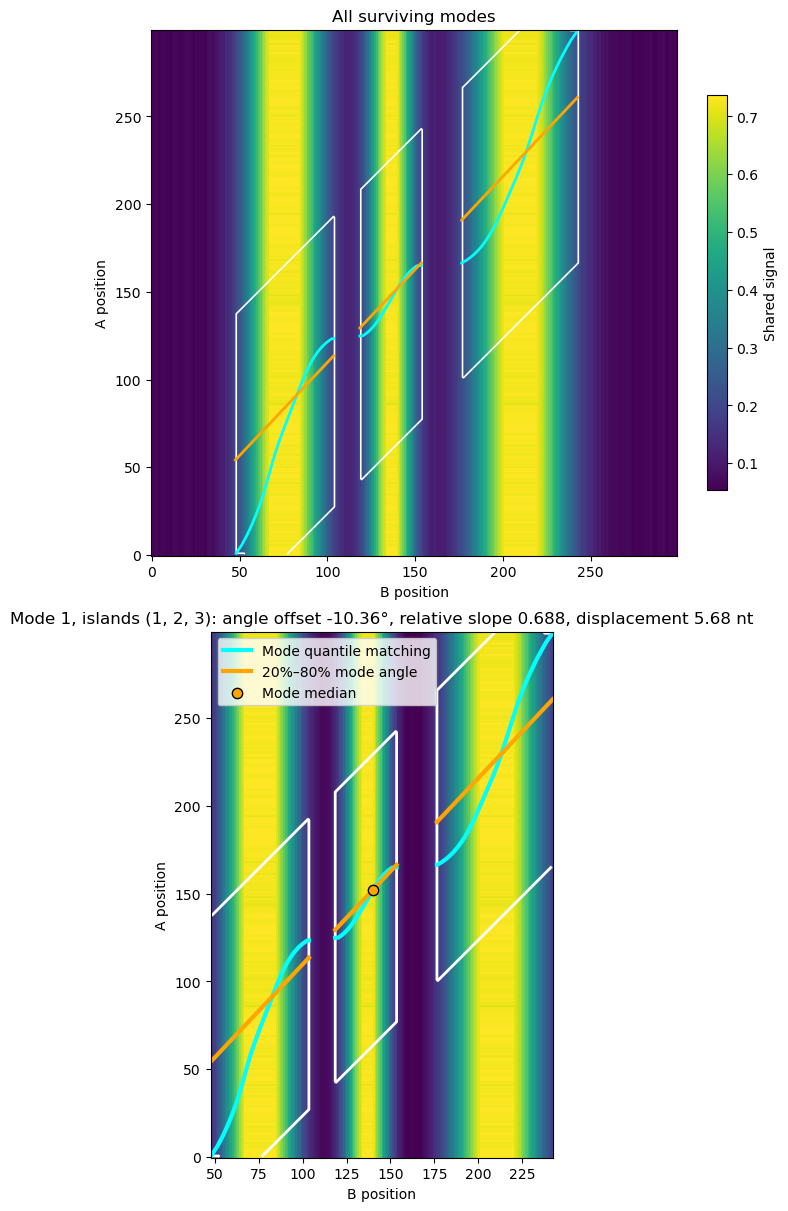

In [9]:
def plot_mode_lines(matrix, modes, mode_lines):
    figure, axes = plt.subplots(
        1 + len(modes), 1,
        figsize=(7, 6 * (1 + len(modes))),
        constrained_layout=True,
        squeeze=False,
    )
    axes = axes[:, 0]

    vmin, vmax = np.percentile(matrix, [1, 99])
    overview = axes[0]
    image = overview.imshow(
        matrix, origin='lower', cmap='viridis', aspect='equal',
        interpolation='nearest', vmin=vmin, vmax=vmax,
    )
    overview.set_title('All surviving modes')
    overview.set_xlabel('B position')
    overview.set_ylabel('A position')

    for index, mode in enumerate(modes):
        mode_id = mode['mode_id']
        line_data = mode_lines[mode_id]
        quantile_x, quantile_y = line_data['visible_quantile']
        straight_x, straight_y = line_data['straight']
        metrics = line_data['metrics']

        overview.contour(
            mode['mask'].astype(float), levels=[0.5], origin='lower',
            colors='white', linewidths=1.2,
        )
        overview.plot(quantile_x, quantile_y, color='cyan', linewidth=2)
        overview.plot(straight_x, straight_y, color='orange', linewidth=2)

        closeup = axes[index + 1]
        crop = mode_crop(matrix, mode)
        mask_crop = mode_crop(mode['mask'], mode)
        crop_vmin, crop_vmax = np.percentile(crop, [2, 98])
        closeup.imshow(
            crop, origin='lower', cmap='viridis', aspect='equal',
            interpolation='nearest', vmin=crop_vmin, vmax=crop_vmax,
            extent=(
                mode['x_min'] - 0.5, mode['x_max'] + 0.5,
                mode['y_min'] - 0.5, mode['y_max'] + 0.5,
            ),
        )
        closeup.contour(
            np.arange(mode['x_min'], mode['x_max'] + 1),
            np.arange(mode['y_min'], mode['y_max'] + 1),
            mask_crop.astype(float), levels=[0.5],
            colors='white', linewidths=2,
        )
        closeup.plot(
            quantile_x, quantile_y, color='cyan', linewidth=3,
            label='Mode quantile matching',
        )
        closeup.plot(
            straight_x, straight_y, color='orange', linewidth=3,
            label=f'{ANGLE_QUANTILES[0]:.0%}–{ANGLE_QUANTILES[1]:.0%} mode angle',
        )
        closeup.scatter(
            metrics['median_b'], metrics['median_a'],
            s=55, color='orange', edgecolor='black', zorder=5, label='Mode median',
        )
        closeup.set_title(
            f"Mode {mode_id}, islands {mode['island_ids']}: "
            f"angle offset {metrics['angle_offset_deg']:.2f}°, "
            f"relative slope {metrics['relative_slope']:.3f}, "
            f"displacement {metrics['median_displacement_nt']:.2f} nt"
        )
        closeup.set_xlabel('B position')
        closeup.set_ylabel('A position')
        closeup.legend(loc='best')

    figure.colorbar(image, ax=overview, shrink=0.75, label='Shared signal')
    return figure, axes


figure, axes = plot_mode_lines(matrix, modes, mode_lines)
plt.show()

# Compare quantile parameters for one mode

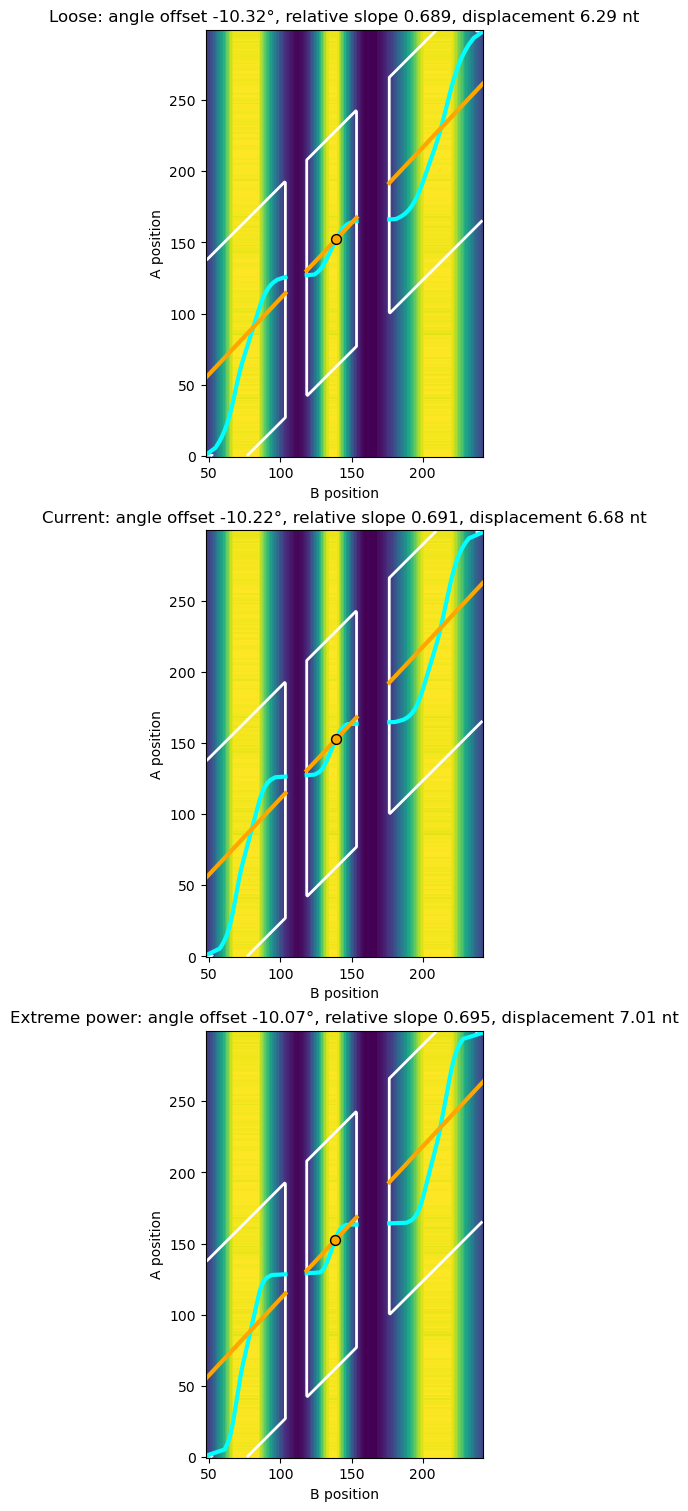

In [10]:
# Change this index to inspect a different surviving mode.
MODE_INDEX = 0

QUANTILE_EXAMPLES = {
    'Loose': {
        'signal_influence': 1.0,
        'signal_power': 2.0,
        'smoothing_sigma': 0.0,
    },
    'Current': {
        'signal_influence': 1.0,
        'signal_power': 3.1,
        'smoothing_sigma': 0.0,
    },
    'Extreme power': {
        'signal_influence': 1.0,
        'signal_power': 5.0,
        'smoothing_sigma': 0.0,
    },
}

mode = modes[MODE_INDEX]
crop = mode_crop(matrix, mode)
mask_crop = mode_crop(mode['mask'], mode)
crop_vmin, crop_vmax = np.percentile(crop, [2, 98])

figure, axes = plt.subplots(
    len(QUANTILE_EXAMPLES), 1,
    figsize=(7, 5 * len(QUANTILE_EXAMPLES)),
    constrained_layout=True,
)
axes = np.atleast_1d(axes)

for axis, (label, parameters) in zip(axes, QUANTILE_EXAMPLES.items()):
    quantile_x, quantile_y = quantile_matching_line(matrix, mode, **parameters)
    visible_x, visible_y = mask_polyline(quantile_x, quantile_y, mode['mask'])
    straight_x, straight_y, metrics = quantile_angle_line(
        quantile_x, quantile_y, mode,
        lower_quantile=ANGLE_QUANTILES[0],
        upper_quantile=ANGLE_QUANTILES[1],
    )
    axis.imshow(
        crop, origin='lower', cmap='viridis', aspect='equal',
        interpolation='nearest', vmin=crop_vmin, vmax=crop_vmax,
        extent=(
            mode['x_min'] - 0.5, mode['x_max'] + 0.5,
            mode['y_min'] - 0.5, mode['y_max'] + 0.5,
        ),
    )
    axis.contour(
        np.arange(mode['x_min'], mode['x_max'] + 1),
        np.arange(mode['y_min'], mode['y_max'] + 1),
        mask_crop.astype(float), levels=[0.5], colors='white', linewidths=2,
    )
    axis.plot(visible_x, visible_y, color='cyan', linewidth=3)
    axis.plot(straight_x, straight_y, color='orange', linewidth=3)
    axis.scatter(
        metrics['median_b'], metrics['median_a'],
        s=50, color='orange', edgecolor='black', zorder=5,
    )
    axis.set_title(
        f"{label}: angle offset {metrics['angle_offset_deg']:.2f}°, "
        f"relative slope {metrics['relative_slope']:.3f}, "
        f"displacement {metrics['median_displacement_nt']:.2f} nt"
    )
    axis.set_xlabel('B position')
    axis.set_ylabel('A position')

plt.show()